Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']

 Decision Tree
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1 Score: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


 Random Forest
Accuracy: 0.9
Precision: 0.9024
Recall: 0.9
F1 Score: 0.8997

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
 

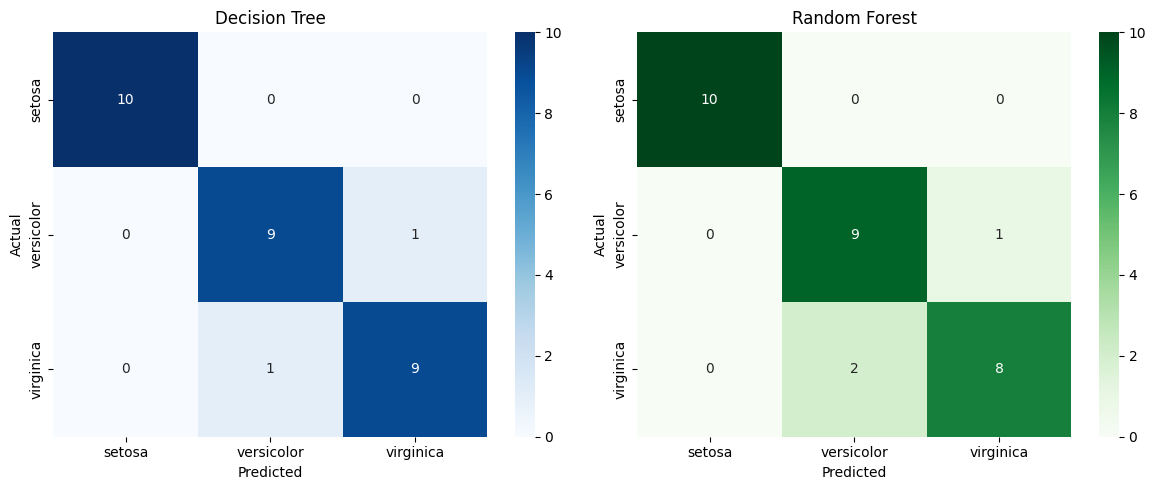


Model Comparison:
           Model  Accuracy  Precision  Recall  F1 Score
0  Decision Tree    0.9333     0.9333  0.9333    0.9333
1  Random Forest    0.9000     0.9024  0.9000    0.8997


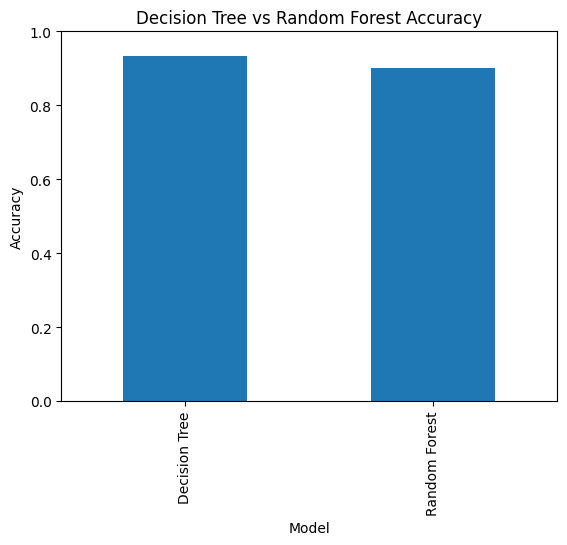

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

# 4. Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# 5. Evaluation function
def evaluate_model(name, y_test, y_pred):
    print("\n", name)

    print("Accuracy:",
          round(accuracy_score(y_test, y_pred), 4))

    print("Precision:",
          round(precision_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("Recall:",
          round(recall_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("F1 Score:",
          round(f1_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names
    ))

# Evaluate both models
evaluate_model("Decision Tree", y_test, dt_pred)
evaluate_model("Random Forest", y_test, rf_pred)

# 6. Confusion matrices
dt_cm = confusion_matrix(y_test, dt_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    dt_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[0]
)
axes[0].set_title("Decision Tree")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    rf_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[1]
)
axes[1].set_title("Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 7. Compare model performance
results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred, average="macro"),
        precision_score(y_test, rf_pred, average="macro")
    ],
    "Recall": [
        recall_score(y_test, dt_pred, average="macro"),
        recall_score(y_test, rf_pred, average="macro")
    ],
    "F1 Score": [
        f1_score(y_test, dt_pred, average="macro"),
        f1_score(y_test, rf_pred, average="macro")
    ]
})

print("\nModel Comparison:")
print(results.round(4))

# 8. Accuracy comparison graph
results.set_index("Model")["Accuracy"].plot(
    kind="bar",
    ylim=(0, 1),
    title="Decision Tree vs Random Forest Accuracy"
)

plt.ylabel("Accuracy")
plt.show()
